# QMI Take-Home Starter: Calibration in Kalshi 15-Minute Markets

**Goal:** go from your coin's raw tables to the **Part A** files (`bins.csv`, `scores.csv`) without leaking the future into your forecasts. This notebook covers Part A only. Parts B and C (your own graphic and design card) are yours to build.

This is the **Data Cleaning Lab, on real market data**. Same skills, higher stakes:

| Lab part | Skill | Where it shows up here |
|---|---|---|
| 1 | Look before you clean | Part 1: profile the three tables |
| 2 | `concat` | Part 2: stack day partitions |
| 3 | Fix dates | Part 3: UTC timestamps; Chicago time for time-of-day |
| 4 | Fix numbers, sentinels | Part 4: empty book sides, mid and spread in the right units |
| 5 | Duplicates and keys | Part 5: one row per market; unique book events |
| 6 | Catch outliers by group | Part 6: wide, one-sided and stale quotes |
| 7 | **Fill without peeking** | Part 7: **as-of join**, the forward fill of this project |
| 8 | Safe `merge` with `validate` | Part 8: attach outcomes |
| 9 | `groupby`, NumPy `axis` | Part 9: bins, Brier score, Murphy decomposition |
| 10 | How much did cleaning matter? | Part 10: your first sensitivity check (Part C) |

**AI rules (same as the lab):** use it like a teammate. You should be able to explain every line you keep, and at the meeting we will ask. Run every **CHECK** cell, and every line should say `PASS` before you move on.

Cells marked `# TODO` are yours. Replace each `...` with code.

## Setup (edit only `DATA_DIR` and `SERIES`)

In [1]:
import glob, os
import numpy as np
import pandas as pd

DATA_DIR = "./KXBNB15M"      # folder you unzipped
SERIES   = "KXBNB15M"        # your assigned series
HORIZONS = [600, 300, 60]    # seconds before close (Part A baseline)
MAX_SPREAD = 0.04            # dollars, i.e. 4 cents (Part A baseline)
N_BINS = 10                  # equal-width bins on [0, 1] (Part A baseline)

def check(label, test):
    """Print PASS/FAIL for a check. `test` is a function returning True/False."""
    try:
        ok = bool(test())
    except Exception as e:
        ok = False
        label += f"  ({type(e).__name__}: {e})"
    print(("PASS  " if ok else "FAIL  ") + label)

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.0 | numpy 2.5.4


In [2]:
check("data folder found", lambda: os.path.exists(f"{DATA_DIR}/markets.parquet"))

PASS  data folder found


## Part 1: Look before you clean

Load `markets.parquet` (all columns), `trades.parquet` (all columns), and **only the level-1 columns** of `bbo`: `ticker, ts_exchange, seq, yes_bid, yes_bid_size, yes_ask, yes_ask_size`. If `bbo` is a folder of day partitions, leave it for Part 2 and load just one day here.

`ticker` is stored as a categorical column; cast it to `str` in every table so joins across files line up. Use `head`, `shape`, `info()` and `describe()`. Also look at `markets["result"].value_counts()` and `markets["quality_flag"].value_counts()`.

In [13]:
BBO_COLS = ["ticker", "ts_exchange", "seq", "yes_bid", "yes_bid_size", "yes_ask", "yes_ask_size"]

# TODO: load markets and trades, inspect all three tables
markets = pd.read_parquet(f"{DATA_DIR}/markets.parquet")
trades = pd.read_parquet(f"{DATA_DIR}/trades.parquet")
bbo_files = sorted(glob.glob(f"{DATA_DIR}/bbo/date=2026-10-*/part.parquet"))   # the pattern from piece 1
print(len(bbo_files), bbo_files[:2])    # sanity check: expect 14 files
bbo = pd.read_parquet(bbo_files[0], columns=BBO_COLS)
markets["ticker"] = markets["ticker"].astype(str)
trades["ticker"] = trades["ticker"].astype(str)
bbo["ticker"] = bbo["ticker"].astype(str)
markets["quality_flag"].value_counts()

14 ['./KXBNB15M/bbo/date=2026-10-08/part.parquet', './KXBNB15M/bbo/date=2026-10-09/part.parquet']


quality_flag
ok     1318
gap       6
Name: count, dtype: int64

In [8]:
markets.head()

,series,ticker,event_ticker,open_time,close_time,floor_strike,result,status,volume,open_interest,rules_primary,first_msg_time,last_msg_time,n_book_msgs,n_trades,quality_flag
0,KXBNB15M,KXBNB15M-26OCT072100-00,KXBNB15M-26OCT072100,2026-10-08 00:45:00+00:00,2026-10-08 01:00:00+00:00,773.08,yes,finalized,11086.87,5308.93,If the simple average of the sixty seconds of ...,2026-10-08 00:43:09.744953352+00:00,2026-10-08 01:00:04.487664183+00:00,49995,1014,gap
1,KXBNB15M,KXBNB15M-26OCT072115-15,KXBNB15M-26OCT072115,2026-10-08 01:00:00+00:00,2026-10-08 01:15:00+00:00,774.02,yes,finalized,18734.29,13613.15,If the simple average of the sixty seconds of ...,2026-10-08 00:50:04.819724962+00:00,2026-10-08 01:15:00.963704355+00:00,56896,1294,ok
2,KXBNB15M,KXBNB15M-26OCT072130-30,KXBNB15M-26OCT072130,2026-10-08 01:15:00+00:00,2026-10-08 01:30:00+00:00,774.89,no,finalized,15907.39,10850.53,If the simple average of the sixty seconds of ...,2026-10-08 01:05:15.646775076+00:00,2026-10-08 01:30:01.487412893+00:00,52378,1092,ok
3,KXBNB15M,KXBNB15M-26OCT072145-45,KXBNB15M-26OCT072145,2026-10-08 01:30:00+00:00,2026-10-08 01:45:00+00:00,773.70,no,finalized,27327.65,6627.52,If the simple average of the sixty seconds of ...,2026-10-08 01:21:20.793605489+00:00,2026-10-08 01:45:00.881174642+00:00,78264,2240,ok
4,KXBNB15M,KXBNB15M-26OCT072200-00,KXBNB15M-26OCT072200,2026-10-08 01:45:00+00:00,2026-10-08 02:00:00+00:00,773.61,no,finalized,18006.16,11568.17,If the simple average of the sixty seconds of ...,2026-10-08 01:35:35.944798797+00:00,2026-10-08 02:00:01.487429822+00:00,54397,1391,ok


In [9]:
markets.shape

(1324, 16)

In [10]:
markets.info()

<class 'pandas.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype              
---  ------          --------------  -----              
 0   series          1324 non-null   category           
 1   ticker          1324 non-null   str                
 2   event_ticker    1324 non-null   str                
 3   open_time       1324 non-null   datetime64[ns, UTC]
 4   close_time      1324 non-null   datetime64[ns, UTC]
 5   floor_strike    1324 non-null   float64            
 6   result          1324 non-null   str                
 7   status          1324 non-null   str                
 8   volume          1324 non-null   float64            
 9   open_interest   1324 non-null   float64            
 10  rules_primary   1324 non-null   str                
 11  first_msg_time  1324 non-null   datetime64[ns, UTC]
 12  last_msg_time   1324 non-null   datetime64[ns, UTC]
 13  n_book_msgs     1324 non-null   int64       

In [11]:
markets.describe()

,floor_strike,volume,open_interest,n_book_msgs,n_trades
count,1324.000000,1324.000000,1324.000000,1324.000000,1324.000000
mean,736.403497,20883.487523,10087.535536,55898.390483,1423.320997
std,13.013921,11778.820666,5414.762743,17201.400879,603.532266
min,705.900000,4331.390000,2362.890000,25736.000000,337.000000
25%,726.430000,13314.397500,6638.670000,43239.250000,1006.750000
50%,738.585000,17970.400000,8636.735000,52821.500000,1294.000000
75%,746.345000,24605.247500,11902.740000,64425.000000,1674.500000
max,774.890000,111351.280000,69186.770000,160102.000000,5040.000000


In [14]:
markets["result"].value_counts()

result
yes    699
no     625
Name: count, dtype: int64

In [ ]:
bbo["ticker"].value_counts()

ticker
KXBNB15M-26OCT081215-15    26576
KXBNB15M-26OCT081145-45    25858
KXBNB15M-26OCT081315-15    23377
KXBNB15M-26OCT081345-45    22270
KXBNB15M-26OCT081000-00    19765
                           ...  
KXBNB15M-26OCT080130-30     4585
KXBNB15M-26OCT072100-00     4582
KXBNB15M-26OCT080545-45     4035
KXBNB15M-26OCT080515-15     3521
KXBNB15M-26OCT082015-15        1
Name: count, Length: 86, dtype: int64

In [16]:
bbo["ticker"].value_counts().describe()

count       86.000000
mean      9563.372093
std       4738.079278
min          1.000000
25%       6902.750000
50%       7801.500000
75%      11923.500000
max      26576.000000
Name: count, dtype: float64

**Write it down:** four things you noticed, such as how many markets you have, the Yes/No split, how many are flagged, and the range of `bbo` rows per market.

1. 1324 markets across the 14 day span
2. 699 resolved to yes, 625 resolved to no
3. 6 flagged with a gap
4. On Oct 8, a typical market’s best price changed about 7,800 times in 15 minutes. The busiest had about 26,600 changes. The minimum of 1 is a market split across midnight.

## Part 2: Stack the day partitions (`concat`)

If your `bbo` came as `bbo/date=YYYY-MM-DD/part.parquet` files, read each file (with `columns=BBO_COLS`) and stack them into one DataFrame with a fresh index. If it is a single file, just load it.

*Think:* you'll sort later anyway. Why does a fresh index still matter?

In [17]:
# TODO: build one bbo DataFrame
paths = sorted(glob.glob(f"{DATA_DIR}/bbo/**/*.parquet", recursive=True)) or [f"{DATA_DIR}/bbo.parquet"]
parts = []
for p in paths:
    df = pd.read_parquet(p, columns=BBO_COLS)
    parts.append(df)
bbo = pd.concat(parts, ignore_index=True)
bbo["ticker"] = bbo["ticker"].astype(str)

In [18]:
# CHECK
check("bbo has every row from every part", lambda: len(bbo) == sum(len(p) for p in parts))
check("index is 0..n-1", lambda: bbo.index.equals(pd.RangeIndex(len(bbo))))
check("only level-1 columns loaded", lambda: list(bbo.columns) == BBO_COLS)
check("ticker is plain text, not categorical", lambda: pd.api.types.is_string_dtype(bbo["ticker"]) and not isinstance(bbo["ticker"].dtype, pd.CategoricalDtype))

PASS  bbo has every row from every part
PASS  index is 0..n-1
PASS  only level-1 columns loaded
PASS  ticker is plain text, not categorical


In [19]:
bbo.shape

(10311092, 7)

## Part 3: Get time right

All timestamps should be timezone-aware **UTC**. Confirm this, and convert anything that isn't. Then add `close_time_ct` to `markets`, the close time in `America/Chicago`. You'll want it for time-of-day splits in Part B.

*Think:* Kalshi's market page shows Eastern time and your laptop may show something else. What goes wrong if you mix a naive timestamp with a UTC one?

In [28]:
# TODO: make sure every timestamp column is UTC, add close_time_ct
# All timestamp columns are in UTC, checked using .info() on markets, trades, and bbo
markets["close_time_ct"] = markets["close_time"].dt.tz_convert("America/Chicago")

In [26]:
markets.info()

<class 'pandas.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype              
---  ------          --------------  -----              
 0   series          1324 non-null   category           
 1   ticker          1324 non-null   str                
 2   event_ticker    1324 non-null   str                
 3   open_time       1324 non-null   datetime64[ns, UTC]
 4   close_time      1324 non-null   datetime64[ns, UTC]
 5   floor_strike    1324 non-null   float64            
 6   result          1324 non-null   str                
 7   status          1324 non-null   str                
 8   volume          1324 non-null   float64            
 9   open_interest   1324 non-null   float64            
 10  rules_primary   1324 non-null   str                
 11  first_msg_time  1324 non-null   datetime64[ns, UTC]
 12  last_msg_time   1324 non-null   datetime64[ns, UTC]
 13  n_book_msgs     1324 non-null   int64       

In [25]:
trades.info()

<class 'pandas.DataFrame'>
RangeIndex: 1884477 entries, 0 to 1884476
Data columns (total 8 columns):
 #   Column       Dtype              
---  ------       -----              
 0   ticker       str                
 1   trade_id     str                
 2   ts_exchange  datetime64[ns, UTC]
 3   ts_recv      datetime64[ns, UTC]
 4   yes_price    float64            
 5   count        float64            
 6   taker_side   category           
 7   is_block     bool               
dtypes: bool(1), category(1), datetime64[ns, UTC](2), float64(2), str(2)
memory usage: 195.9 MB


In [27]:
bbo.info()

<class 'pandas.DataFrame'>
RangeIndex: 10311092 entries, 0 to 10311091
Data columns (total 7 columns):
 #   Column        Dtype              
---  ------        -----              
 0   ticker        str                
 1   ts_exchange   datetime64[ns, UTC]
 2   seq           int64              
 3   yes_bid       float64            
 4   yes_bid_size  float64            
 5   yes_ask       float64            
 6   yes_ask_size  float64            
dtypes: datetime64[ns, UTC](1), float64(4), int64(1), str(1)
memory usage: 776.8 MB


In [29]:
# CHECK
check("market times are UTC", lambda: str(markets["close_time"].dt.tz) == "UTC" and str(markets["open_time"].dt.tz) == "UTC")
check("bbo times are UTC", lambda: str(bbo["ts_exchange"].dt.tz) == "UTC")
check("every market lasts 15 minutes", lambda: ((markets["close_time"] - markets["open_time"]) == pd.Timedelta(minutes=15)).all())
check("close_time_ct is Chicago time", lambda: str(markets["close_time_ct"].dt.tz) == "America/Chicago")

PASS  market times are UTC
PASS  bbo times are UTC
PASS  every market lasts 15 minutes
PASS  close_time_ct is Chicago time


## Part 4: Numbers and units

1. An empty side of the book is stored as **missing** (`NaN`). Make sure it stays missing. Never fill it with 0 or 100, because that is the `-999` trap from the lab in disguise.
2. Prices are **dollars per contract** (a contract pays $1.00), so a price already *is* a probability. Add `spread = yes_ask - yes_bid` and `mid = (yes_bid + yes_ask) / 2`. Both should be `NaN` whenever either side is missing.
3. Prices are exact multiples of $0.001, but floating-point subtraction isn't exact (0.53 − 0.49 can come out as 0.04000000000000001). Round `spread` to 3 decimals so the `<= 0.04` filter behaves.

*Think:* some prices look like 0.997 and some like 0.53. Why? (Kalshi's tick size changes near the extremes.)

In [33]:
# TODO: spread and mid (both in dollars = probability units)
bbo["spread"] = (bbo["yes_ask"] - bbo["yes_bid"]).round(3)
bbo["mid"] = (bbo["yes_bid"] + bbo["yes_ask"])/2

In [30]:
bbo.info()

<class 'pandas.DataFrame'>
RangeIndex: 10311092 entries, 0 to 10311091
Data columns (total 7 columns):
 #   Column        Dtype              
---  ------        -----              
 0   ticker        str                
 1   ts_exchange   datetime64[ns, UTC]
 2   seq           int64              
 3   yes_bid       float64            
 4   yes_bid_size  float64            
 5   yes_ask       float64            
 6   yes_ask_size  float64            
dtypes: datetime64[ns, UTC](1), float64(4), int64(1), str(1)
memory usage: 776.8 MB


In [34]:
bbo["yes_bid"].isna().sum()

np.int64(30639)

In [35]:
bbo["yes_ask"].isna().sum()

np.int64(31326)

In [36]:
bbo["spread"].isna().sum()

np.int64(58346)

In [37]:
bbo["mid"].isna().sum()

np.int64(58346)

In [38]:
# CHECK
both = bbo["yes_bid"].notna() & bbo["yes_ask"].notna()
check("prices are dollars strictly between 0 and 1", lambda: all(bbo[c].dropna().between(0.0005, 0.9995).all() for c in ["yes_bid", "yes_ask"]))
check("prices sit on the $0.001 grid", lambda: all(((bbo[c].dropna() * 1000).round() - bbo[c].dropna() * 1000).abs().max() < 1e-6 for c in ["yes_bid", "yes_ask"]))
check("spread is rounded to 3 decimals", lambda: (bbo["spread"].dropna().round(3) == bbo["spread"].dropna()).all())
check("no crossed or locked books", lambda: (bbo.loc[both, "spread"] > 0).all())
check("mid is a probability", lambda: bbo["mid"].dropna().between(0, 1).all())
check("mid is missing exactly when a side is missing", lambda: (bbo["mid"].isna() == ~both).all())

PASS  prices are dollars strictly between 0 and 1
PASS  prices sit on the $0.001 grid
PASS  spread is rounded to 3 decimals
PASS  no crossed or locked books
PASS  mid is a probability
PASS  mid is missing exactly when a side is missing


## Part 5: Keys and duplicates

1. `markets` must have exactly one row per `ticker`, and every `result` must be `yes` or `no`.
2. Each book event `(ticker, ts_exchange, seq)` should appear once. Drop exact duplicate rows if there are any, then confirm.
3. Every `bbo` ticker should exist in `markets`. Count any that don't (these are *orphans*).

In [52]:
# TODO: dedupe and count orphans
bbo.duplicated(subset=["ticker", "ts_exchange", "seq"]).sum() # there are no duplicates
bbo = bbo.drop_duplicates()
orphans = (~(bbo["ticker"].isin(markets["ticker"].unique()))).sum()     # number of bbo rows whose ticker is not in markets
print("orphan rows:", orphans)

orphan rows: 0


In [39]:
len(markets)

1324

In [40]:
markets["ticker"].nunique()

1324

In [ ]:
markets["result"].isin(["yes", "no"]).all()

np.True_

In [46]:
bbo.duplicated(subset=["ticker", "ts_exchange", "seq"]).sum()

np.int64(0)

In [49]:
bbo["ticker"].isin(markets["ticker"].unique()).all()

np.True_

In [53]:
# CHECK
check("one row per market", lambda: markets["ticker"].is_unique)
check("results are yes/no only", lambda: set(markets["result"]) <= {"yes", "no"})
check("book events are unique", lambda: not bbo.duplicated(subset=["ticker", "ts_exchange", "seq"]).any())
check("no orphan bbo rows", lambda: orphans == 0)

PASS  one row per market
PASS  results are yes/no only
PASS  book events are unique
PASS  no orphan bbo rows


## Part 6: Suspicious quotes

In the lab, a price 10x its ticker's median was a decimal slip. Here the suspicious things are different:

1. **Wide books:** `spread > MAX_SPREAD`.
2. **One-sided books:** exactly one of `yes_bid` and `yes_ask` is missing.
3. Per market, the **share of book updates that are wide or one-sided**. Use `groupby("ticker")` with a mean of a boolean column. List the 5 worst markets.

Don't delete anything yet. In this project, filtering is a decision you make at the snapshot (Part 7) and must report in Part C.

In [54]:
# TODO: flag rows, then rank markets
bbo["wide"] = bbo["spread"] > MAX_SPREAD
bbo["one_sided"] = bbo["yes_bid"].isna() != bbo["yes_ask"].isna()
bbo["bad"] = bbo["wide"] | bbo["one_sided"]
bad_share = bbo.groupby("ticker")["bad"].mean()     # Series indexed by ticker
print(bad_share.sort_values(ascending=False).head())

ticker
KXBNB15M-26OCT101645-45    0.534774
KXBNB15M-26OCT100800-00    0.495398
KXBNB15M-26OCT101830-30    0.458545
KXBNB15M-26OCT101915-15    0.453531
KXBNB15M-26OCT091945-45    0.447861
Name: bad, dtype: float64


In [55]:
# CHECK
check("wide is boolean", lambda: bbo["wide"].dtype == bool)
check("one-sided rows have exactly one side", lambda: (bbo.loc[bbo["one_sided"], ["yes_bid", "yes_ask"]].notna().sum(axis=1) == 1).all())
check("one share per market, between 0 and 1", lambda: bad_share.between(0, 1).all() and bad_share.index.is_unique)

PASS  wide is boolean
PASS  one-sided rows have exactly one side
PASS  one share per market, between 0 and 1


## Part 7: Snapshot without peeking (the most important part)

In the lab, forward fill used each ticker's **last known** price, and `interpolate()` quietly used the future. The same trap exists here.

For each market and each horizon `h` in `HORIZONS`, you want the book **as it stood** at `close_time - h`. That means the latest `bbo` row at or before that moment, **for that ticker only**. This is `pd.merge_asof(..., by="ticker", direction="backward")`, which is a forward fill done as a join.

1. Build `targets`: one row per (market, horizon) with columns `ticker, horizon_sec, t`.
2. `merge_asof` the book onto `targets`. Both sides must be sorted by time. Each market has at most one `bbo` row per millisecond, so sorting by `ts_exchange` is enough; adding `seq` as a tiebreaker (`["ts_exchange", "seq"]`) is a harmless safety net.
3. Add `quote_age = t - ts_exchange`, which tells you how stale each snapshot is.

**Think:** what would `direction="nearest"` do, and why is it the `interpolate()` bug in disguise?

In [56]:
# TODO: targets, as-of join, quote age
pieces = []
for h in HORIZONS:
    piece = markets[["ticker", "close_time"]].copy()
    piece["horizon_sec"] = h
    piece["t"] = piece["close_time"] - pd.Timedelta(seconds=h)
    pieces.append(piece)
targets = pd.concat(pieces, ignore_index=True)
targets = targets.sort_values("t")
bbo = bbo.sort_values(["ts_exchange", "seq"])
snap = pd.merge_asof(targets, bbo, left_on="t", right_on="ts_exchange", by="ticker", direction="backward")
snap["quote_age"] = snap["t"] - snap["ts_exchange"]

In [57]:
# CHECK
check("one row per market per horizon", lambda: len(snap) == len(markets) * len(HORIZONS))
check("no quote comes from the future", lambda: (snap["ts_exchange"].dropna() <= snap.loc[snap["ts_exchange"].notna(), "t"]).all())
check("no quote comes from before the market opened",
      lambda: (snap["ts_exchange"].dropna() >= snap.loc[snap["ts_exchange"].notna(), "ticker"].map(markets.set_index("ticker")["open_time"]) - pd.Timedelta(minutes=10)).all())
check("quote_age is never negative", lambda: (snap["quote_age"].dropna() >= pd.Timedelta(0)).all())
print(snap.groupby("horizon_sec")["quote_age"].describe())

PASS  one row per market per horizon
PASS  no quote comes from the future
PASS  no quote comes from before the market opened
PASS  quote_age is never negative
            count                       mean                        std  \
horizon_sec                                                               
60           1324  0 days 00:00:02.961443353  0 days 00:00:12.145454530   
300          1324  0 days 00:00:00.629259063  0 days 00:00:01.715565933   
600          1324  0 days 00:00:00.430987915  0 days 00:00:00.572961939   

                         min                     25%                     50%  \
horizon_sec                                                                    
60           0 days 00:00:00  0 days 00:00:00.104750  0 days 00:00:00.804000   
300          0 days 00:00:00  0 days 00:00:00.065750  0 days 00:00:00.212000   
600          0 days 00:00:00  0 days 00:00:00.069000  0 days 00:00:00.245000   

                                75%                     max  
ho

In [60]:
snap["mid"].isna().sum()

np.int64(619)

## Part 8: Attach outcomes safely (`merge` + `validate`)

1. Left-merge `markets[["ticker", "result", "quality_flag"]]` onto `snap` with `validate="many_to_one"`. Call the result `panel`.
2. Add `y = 1` for a Yes result, otherwise `0`.
3. Apply the **Part A baseline exclusion:** keep a row only if both sides exist and `spread <= MAX_SPREAD`. Call the kept rows `obs`, and record how many rows each horizon lost in `n_excluded` (a Series indexed by `horizon_sec`).

*Think:* the lab's merge silently added `XYZ`. What would a silent problem look like here?

In [61]:
# TODO: merge outcomes, build y, apply exclusion
panel = snap.merge(markets[["ticker", "result", "quality_flag"]], on="ticker", how="left", validate="many_to_one")
panel["y"] = (panel["result"] == "yes").astype(int)
keep = panel["mid"].notna() & (panel["spread"] <= MAX_SPREAD)
obs = panel[keep]
n_excluded = (~keep).groupby(panel["horizon_sec"]).sum()

In [62]:
# CHECK
check("merge did not add or drop rows", lambda: len(panel) == len(snap))
check("every row has an outcome", lambda: panel["result"].notna().all())
check("y is 0/1", lambda: set(panel["y"].unique()) <= {0, 1})
check("kept + excluded = all rows", lambda: len(obs) + int(n_excluded.sum()) == len(panel))
check("kept rows all pass the filter", lambda: (obs["spread"] <= MAX_SPREAD).all() and obs["mid"].notna().all())
print("excluded per horizon:", n_excluded.to_dict())

PASS  merge did not add or drop rows
PASS  every row has an outcome
PASS  y is 0/1
PASS  kept + excluded = all rows
PASS  kept rows all pass the filter
excluded per horizon: {60: 696, 300: 17, 600: 16}


## Part 9: Bin, score, and write Part A

For each horizon:

1. Put `mid` into `N_BINS` equal-width bins on [0, 1] (`pd.cut` or `np.digitize`; include 1.0).
2. Per bin, compute `n`, `mean_price` (mean of `mid`), `yes_rate` (mean of `y`), and a **Wilson 95%** interval `ci_lo, ci_hi`. Look up the formula; one line of NumPy will do.
3. Per horizon, compute the Brier score `mean((mid - y)^2)` and the Murphy decomposition:
   - `REL = Σ n_k (mean_price_k − yes_rate_k)² / N`
   - `RES = Σ n_k (yes_rate_k − ȳ)² / N`
   - `UNC = ȳ (1 − ȳ)`
   - `BSS = 1 − brier / 0.25`

Then write `bins.csv` and `scores.csv` with **exactly** the Part A columns.

*Heads-up:* with binned forecasts, `REL − RES + UNC` is close to the Brier score but not exactly equal. The gap comes from prices varying *within* each bin. The check below allows for it, and it is worth a sentence in your write-up.

In [63]:
# TODO: bins, Wilson intervals, scores
def wilson(k, n, z=1.96):
    p = k / n
    denom  = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half   = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

edges = np.round(np.linspace(0, 1, N_BINS + 1), 4)   # 0.0, 0.1, ..., 1.0
obs = obs.copy()
obs["bin"] = pd.cut(obs["mid"].round(4), bins=edges,
                    include_lowest=True, labels=False).astype(int)

bins = (obs.groupby(["horizon_sec", "bin"])
           .agg(n=("y", "size"), k=("y", "sum"),
                mean_price=("mid", "mean"), yes_rate=("y", "mean"))
           .reset_index())
bins["bin_lo"] = edges[bins["bin"]]
bins["bin_hi"] = edges[bins["bin"] + 1]
bins["ci_lo"], bins["ci_hi"] = wilson(bins["k"], bins["n"])
bins["series"] = SERIES
bins = bins[["series", "horizon_sec", "bin_lo", "bin_hi", "n",
             "mean_price", "yes_rate", "ci_lo", "ci_hi"]]

rows = []
for h, g in obs.groupby("horizon_sec"):
    b = bins[bins["horizon_sec"] == h]
    N = len(g)
    ybar = g["y"].mean()
    brier = ((g["mid"] - g["y"]) ** 2).mean()
    rows.append({
        "series": SERIES, "horizon_sec": h, "n_markets": N,
        "n_excluded": int(n_excluded[h]),
        "brier": brier,
        "rel": (b["n"] * (b["mean_price"] - b["yes_rate"]) ** 2).sum() / N,
        "res": (b["n"] * (b["yes_rate"] - ybar) ** 2).sum() / N,
        "unc": ybar * (1 - ybar),
        "bss": 1 - brier / 0.25,
    })
scores = pd.DataFrame(rows)

bins.to_csv("bins.csv", index=False)
scores.to_csv("scores.csv", index=False)

In [64]:
# CHECK
BIN_COLS = ["series", "horizon_sec", "bin_lo", "bin_hi", "n", "mean_price", "yes_rate", "ci_lo", "ci_hi"]
SCORE_COLS = ["series", "horizon_sec", "n_markets", "n_excluded", "brier", "rel", "res", "unc", "bss"]
check("bins.csv has exactly the Part A columns", lambda: list(pd.read_csv("bins.csv").columns) == BIN_COLS)
check("scores.csv has exactly the Part A columns", lambda: list(pd.read_csv("scores.csv").columns) == SCORE_COLS)
check("one score row per horizon", lambda: sorted(scores["horizon_sec"]) == sorted(HORIZONS))
check("bin counts add up to kept markets", lambda: (bins.groupby("horizon_sec")["n"].sum() == scores.set_index("horizon_sec")["n_markets"]).all())
check("intervals contain the yes rate", lambda: ((bins["ci_lo"] <= bins["yes_rate"] + 1e-9) & (bins["yes_rate"] <= bins["ci_hi"] + 1e-9)).all())
check("REL - RES + UNC is close to Brier (within 0.01)", lambda: (abs(scores["rel"] - scores["res"] + scores["unc"] - scores["brier"]) < 0.01).all())
check("scores are sane", lambda: scores["brier"].between(0, 1).all() and (scores["rel"] >= 0).all())

PASS  bins.csv has exactly the Part A columns
PASS  scores.csv has exactly the Part A columns
PASS  one score row per horizon
PASS  bin counts add up to kept markets
PASS  intervals contain the yes rate
PASS  REL - RES + UNC is close to Brier (within 0.01)
PASS  scores are sane


## Part 10 (start of Part C): How much did your choices matter?

Rerun Parts 7–9 changing **one** thing at a time, and compare REL and BSS at the 60-second horizon:

1. `direction="nearest"` instead of `"backward"`. This one is **wrong** on purpose: how much does peeking flatter the market?
2. `MAX_SPREAD = 0.10` instead of 0.04.
3. `N_BINS = 5` and `N_BINS = 20`.

Put the results in a small table. Which choices change your headline, and which don't? That table is the seed of your Part C sensitivity section.

*Tip:* wrap Parts 7–9 in a function `run(direction, max_spread, n_bins)` that returns `scores`.

In [65]:
def run(direction="backward", max_spread=MAX_SPREAD, n_bins=N_BINS):
    # Part 7: snapshot
    s = pd.merge_asof(targets, bbo, left_on="t", right_on="ts_exchange",
                      by="ticker", direction=direction)
    # Part 8: attach outcomes, apply filter
    p = s.merge(markets[["ticker", "result", "quality_flag"]], on="ticker",
                how="left", validate="many_to_one")
    p["y"] = (p["result"] == "yes").astype(int)
    keep = p["mid"].notna() & (p["spread"] <= max_spread)
    o = p[keep].copy()
    excl = (~keep).groupby(p["horizon_sec"]).sum()
    # Part 9: bins and scores
    edges = np.round(np.linspace(0, 1, n_bins + 1), 4)
    o["bin"] = pd.cut(o["mid"].round(4), bins=edges,
                      include_lowest=True, labels=False).astype(int)
    b_all = (o.groupby(["horizon_sec", "bin"])
               .agg(n=("y", "size"), mean_price=("mid", "mean"), yes_rate=("y", "mean"))
               .reset_index())
    rows = []
    for h, g in o.groupby("horizon_sec"):
        b = b_all[b_all["horizon_sec"] == h]
        N, ybar = len(g), g["y"].mean()
        brier = ((g["mid"] - g["y"]) ** 2).mean()
        rows.append({
            "series": SERIES, "horizon_sec": h, "n_markets": N,
            "n_excluded": int(excl[h]), "brier": brier,
            "rel": (b["n"] * (b["mean_price"] - b["yes_rate"]) ** 2).sum() / N,
            "res": (b["n"] * (b["yes_rate"] - ybar) ** 2).sum() / N,
            "unc": ybar * (1 - ybar), "bss": 1 - brier / 0.25,
        })
    return pd.DataFrame(rows)

configs = [
    ("baseline",          {}),
    ("nearest (peeking)", {"direction": "nearest"}),
    ("spread <= 10c",     {"max_spread": 0.10}),
    ("5 bins",            {"n_bins": 5}),
    ("20 bins",           {"n_bins": 20}),
]
results = []
for name, settings in configs:
    row = run(**settings).query("horizon_sec == 60").iloc[0]
    results.append({"setting": name, "n_markets": row["n_markets"],
                    "brier": row["brier"], "rel": row["rel"], "bss": row["bss"]})
sens = pd.DataFrame(results)
print(sens.round(4))

             setting  n_markets   brier     rel     bss
0           baseline        628  0.0425  0.0021  0.8301
1  nearest (peeking)        621  0.0406  0.0020  0.8376
2      spread <= 10c        703  0.0563  0.0031  0.7748
3             5 bins        628  0.0425  0.0005  0.8301
4            20 bins        628  0.0425  0.0036  0.8301


## Wrap-up (answer in a sentence each)

1. Which mistake in this pipeline would have done the most damage to the final result if you hadn't caught it? Not turning ticker into plain text. The tables wouldn’t have matched up, so every market would have looked like it ended “No,” and all my scores would have been wrong without any error message.

2. Name one place where a join or filter could have silently changed your numbers with no error. The spread filter. At 1 minute before close, it threw out 696 of 1,324 markets without any warning. When I loosened it from 4¢ to 10¢, the skill score dropped from 0.83 to 0.77, because the strict filter was removing the hardest markets to predict.

3. Pick one line of code AI wrote for you. Explain what it does without looking it up. pd.cut(...) puts each market’s price into one of 10 buckets: 0–10¢, 10–20¢, and so on. I round the price first so tiny computer math errors don’t put a price like 30¢ in the wrong bucket.

In [67]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 18.7 MB/s  0:00:00 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 11.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 15.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


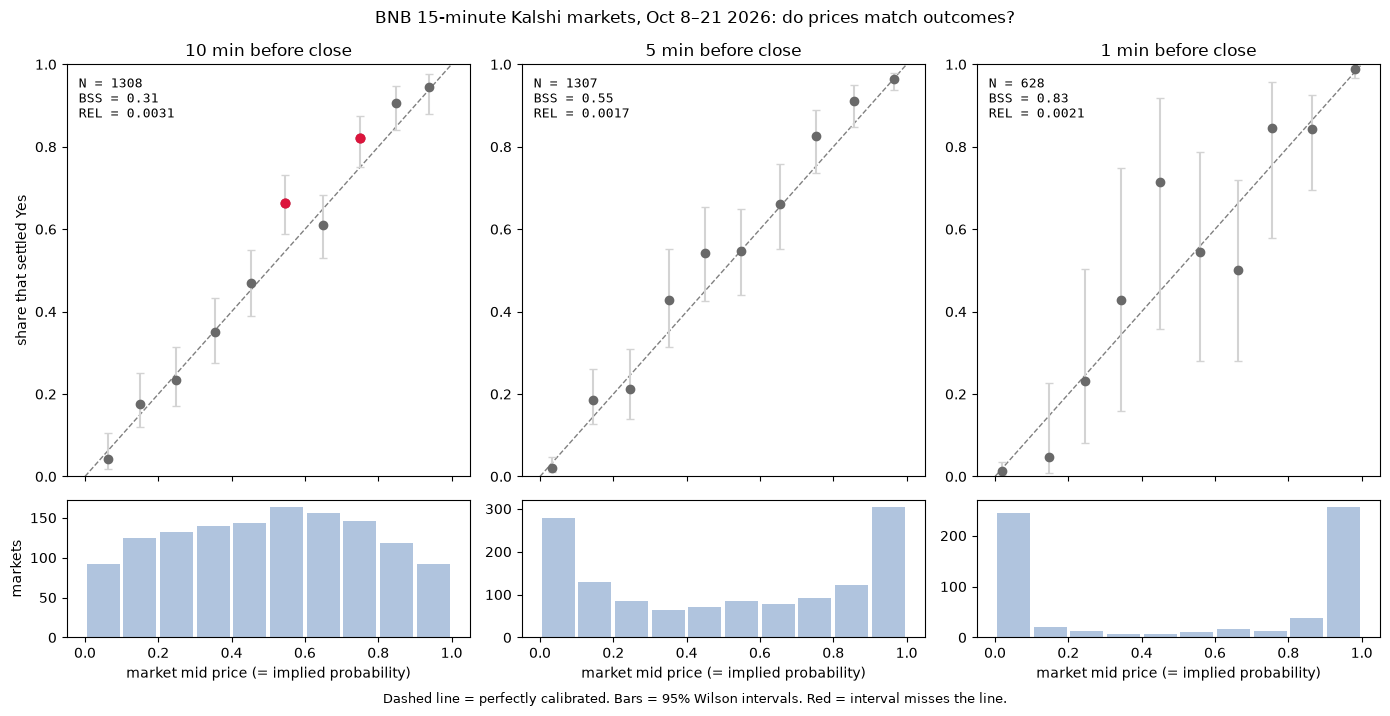

In [68]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

for i, h in enumerate([600, 300, 60]):
    b = bins[bins["horizon_sec"] == h]
    s = scores[scores["horizon_sec"] == h].iloc[0]
    ax, axn = axes[0, i], axes[1, i]

    # diagonal = perfectly honest market
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)

    # dots with Wilson error bars
    ax.errorbar(b["mean_price"], b["yes_rate"],
                yerr=[b["yes_rate"] - b["ci_lo"], b["ci_hi"] - b["yes_rate"]],
                fmt="o", color="dimgray", ecolor="lightgray", capsize=3)

    # highlight bins whose interval misses the diagonal
    miss = (b["ci_hi"] < b["mean_price"]) | (b["ci_lo"] > b["mean_price"])
    ax.scatter(b.loc[miss, "mean_price"], b.loc[miss, "yes_rate"],
               color="crimson", zorder=3, s=40)

    ax.set_title(f"{h // 60} min before close")
    ax.set_ylim(0, 1)
    ax.text(0.03, 0.97,
            f"N = {int(s['n_markets'])}\nBSS = {s['bss']:.2f}\nREL = {s['rel']:.4f}",
            transform=ax.transAxes, va="top", family="monospace", fontsize=9)

    # how many markets in each bin
    axn.bar((b["bin_lo"] + b["bin_hi"]) / 2, b["n"],
            width=(b["bin_hi"] - b["bin_lo"]) * 0.9, color="lightsteelblue")
    axn.set_xlabel("market mid price (= implied probability)")

axes[0, 0].set_ylabel("share that settled Yes")
axes[1, 0].set_ylabel("markets")
fig.suptitle("BNB 15-minute Kalshi markets, Oct 8–21 2026: do prices match outcomes?")
fig.text(0.5, -0.01, "Dashed line = perfectly calibrated. Bars = 95% Wilson intervals. "
         "Red = interval misses the line.", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig("calibration_chart.png", dpi=200, bbox_inches="tight")
plt.show()

## Design card: BNB (KXBNB15M)

| Knob | My choice | Rejected | Why |
|---|---|---|---|
| Price | Mid | Last trade | BNB quotes update several times a second (median quote age 0.27 s), so the mid is current |
| Quote filter | Spread ≤ 4¢ | ≤ 10¢ | Matches Part A. Loosening keeps 75 more markets at 1 min but lowers BSS from 0.83 to 0.77 |
| Moments | 10, 5, 1 min before close | Every tick | One snapshot per moment shows how accuracy changes as close approaches |
| Counting | One per market per moment | Every update | Thousands of updates share one outcome; counting them all would fake a huge sample |
| Grouping | 10 equal bins | 5 or 20 | BSS doesn't change, but REL ranges 0.0005–0.0036, so I don't lean on one REL number |
| Uncertainty | Wilson 95% | Textbook normal interval | Stays between 0 and 1 near the extremes, where most 1-min markets sit |
| What to drop | One-sided or wide books; kept the 6 gap markets | Drop gap markets | Only 6 of 1,324. Max quote age was 3 min 23 s, likely one of them |
| Scores | Brier, REL, BSS | Log loss | Log loss blows up on prices near 0 or 1, which dominate at 1 min |
| Splits | None | Day vs. night | Would halve already-thin middle bins |
| Chart | 3 panels, count bars, red for misses | One overlaid curve | Shows how thin the middle bins get at 1 min |

### Sensitivity checks (1 min before close)

| Setting | Markets | Brier | REL | BSS |
|---|---|---|---|---|
| Baseline | 628 | 0.0425 | 0.0021 | 0.83 |
| Nearest (peeking) | 621 | 0.0406 | 0.0020 | 0.84 |
| Spread ≤ 10¢ | 703 | 0.0563 | 0.0031 | 0.77 |
| 5 bins | 628 | 0.0425 | 0.0005 | 0.83 |
| 20 bins | 628 | 0.0425 | 0.0036 | 0.83 |

### Findings

BNB's 15-minute markets are well calibrated at all three moments, and skill rises from BSS 0.31 at 10 minutes to 0.83 at 1 minute. At 10 minutes, two bins settled Yes more often than priced (about 55¢ → 66% and 75¢ → 82%), but with about 30 intervals at 95%, one or two misses are expected by chance, so I treat this as a hint, not a finding. There is no sign of a favorite–longshot bias: the cheapest and most expensive bins sit on the diagonal.

**What survived:** good calibration at every moment and every setting tested. Peeking barely changes the result (BSS 0.83 → 0.84) because BNB's quotes update so often.

**What didn't:** the exact 1-minute skill depends on the spread filter (0.83 vs. 0.77), because the strict filter drops 696 of 1,324 markets, mostly the hardest ones. The exact REL depends on bin count, so I report it as "small" rather than as a precise number.